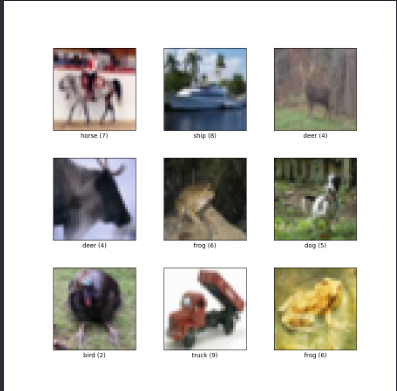

In [1]:
images= ["Airplane", "Automobile", "Bird", "Cat", "Deer", "Dog", "Frog","Horse", "Ship", "Truck"]

In [2]:
images

['Airplane',
 'Automobile',
 'Bird',
 'Cat',
 'Deer',
 'Dog',
 'Frog',
 'Horse',
 'Ship',
 'Truck']

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow

In [4]:
from tensorflow.keras.models import Model

In [5]:
from tensorflow.keras.layers import Input, Dense, Flatten

In [6]:
from tensorflow.keras.datasets import cifar10

In [7]:
(xtrain, ytrain), (xtest,ytest)= cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2581s 15us/step


In [8]:
xtrain.shape

(50000, 32, 32, 3)

In [9]:
xtest.shape

(10000, 32, 32, 3)

array([[[ 60,  82,  54],
        [ 40,  68,  36],
        [ 52,  81,  52],
        ...,
        [ 53,  43,  50],
        [ 66,  55,  61],
        [ 73,  62,  68]],

       [[112, 114, 114],
        [ 58,  71,  56],
        [ 58,  81,  53],
        ...,
        [ 54,  47,  53],
        [ 67,  58,  65],
        [ 72,  62,  69]],

       [[170, 161, 178],
        [119, 118, 120],
        [ 80,  89,  74],
        ...,
        [ 56,  50,  56],
        [ 70,  63,  70],
        [ 72,  64,  71]],

       ...,

       [[ 91, 113,  94],
        [ 59,  83,  62],
        [ 45,  65,  45],
        ...,
        [ 32,  56,  30],
        [ 26,  46,  26],
        [ 25,  42,  23]],

       [[ 99, 119, 102],
        [ 64,  86,  67],
        [ 55,  75,  55],
        ...,
        [ 42,  71,  39],
        [ 42,  68,  37],
        [ 40,  64,  32]],

       [[105, 122, 108],
        [ 70,  92,  74],
        [ 59,  79,  60],
        ...,
        [ 43,  66,  40],
        [ 46,  70,  42],
        [ 45,  71,  40]]], dtype=uint8)
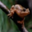

In [10]:
xtrain[5000]

In [11]:
ytrain[5000]

array([6], dtype=uint8)

In [12]:
images[6]

'Frog'

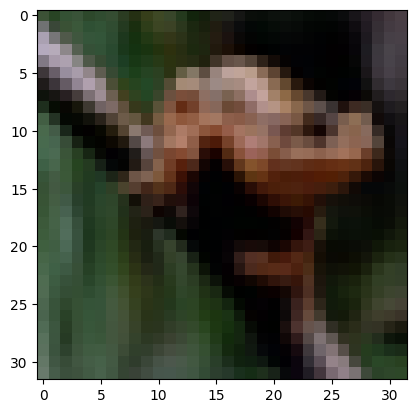

In [13]:
plt.imshow(xtrain[5000])

Data Scaling

In [14]:
xtrain_scale = xtrain/255

In [15]:
xtest_scale= xtest/255

In [16]:
xtrain_scale.max()

np.float64(1.0)

Model Building

In [17]:
from tensorflow.keras.models import Model

In [18]:
from tensorflow.keras.layers import Flatten, Input, Dense

In [19]:
ip= Input(shape=(32,32,3))

In [20]:
flat = Flatten()(ip)

In [21]:
dense1= Dense(128, activation='relu')(flat)

In [22]:
dense2= Dense(256, activation='relu')(dense1)

In [23]:
dense3 = Dense(512, activation='relu')(dense2)

In [24]:
dense4 = Dense(256, activation='relu')(dense3)

In [25]:
dense5= Dense(128, activation='relu')(dense4)

In [26]:
op= Dense(10, activation='softmax')(dense5)

In [27]:
func_model = Model(inputs=ip, outputs=op)

In [28]:
func_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 723,466 (2.76 MB)

 Trainable params: 723,466 (2.76 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
func_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [30]:
func_model.fit(xtrain_scale, ytrain, epochs=10, batch_size=64)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.3054 - loss: 1.8937
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.3838 - loss: 1.7033
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.4136 - loss: 1.6204
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.4339 - loss: 1.5674
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.4500 - loss: 1.5274
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.4626 - loss: 1.4946
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.4716 - loss: 1.4661
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.4851 - loss: 1.4312
Epoch 9/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - accuracy: 0.4940 - loss: 1.4064
Epoch 10/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - accuracy: 0.5041 - loss: 1.3769


In [31]:
func_model.evaluate(xtest_scale, ytest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4597 - loss: 1.5252


[1.525225043296814, 0.45969998836517334]

In [32]:
xtrain_scale[1200].shape

(32, 32, 3)

In [33]:
func_model.predict(xtrain_scale[1200].reshape((1,)+xtrain_scale[1200].shape))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step


array([[0.01051908, 0.00442266, 0.08092523, 0.0338292 , 0.08879882,
        0.05511564, 0.12515363, 0.58361113, 0.00087667, 0.01674794]],
      dtype=float32)

In [34]:
np.argmax(func_model.predict(xtrain_scale[1200].reshape((1,)+xtrain_scale[1200].shape)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


np.int64(7)

In [35]:
images[6]

'Frog'

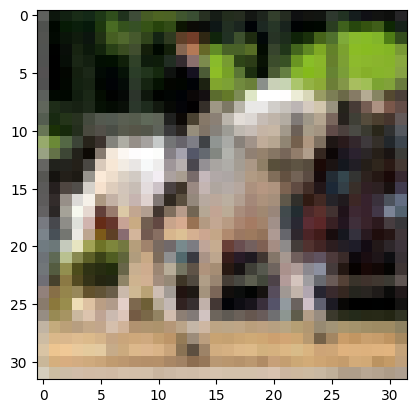

In [36]:
plt.imshow(xtrain_scale[1200])

In [38]:
from google.colab import files
uploaded = files.upload()

Saving Happy Golden Retriever Puppy.png to Happy Golden Retriever Puppy.png


Predicting the image from outside

In [39]:
from PIL import Image
import numpy as np

# Load image
img = Image.open(next(iter(uploaded)))

# Make sure it is RGB
img = img.convert("RGB")

# Resize to 32x32
img = img.resize((32, 32))

# Convert to numpy array
img_array = np.array(img)

print("Image shape:", img_array.shape)

Image shape: (32, 32, 3)


In [40]:
img_array = np.expand_dims(img_array, axis=0)

print("Prediction input shape:", img_array.shape)

Prediction input shape: (1, 32, 32, 3)


In [41]:
func_model.predict(img_array)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step


array([[0.00000000e+00, 0.00000000e+00, 1.03362774e-35, 0.00000000e+00,
        0.00000000e+00, 1.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00]], dtype=float32)

In [42]:
np.argmax(func_model.predict(img_array))



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


np.int64(5)

In [43]:
images[3]

'Cat'

### **Convolutional Neural network**

In [44]:
from tensorflow.keras.models import Sequential

In [45]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

In [46]:
cnn_model = Sequential()

In [47]:
cnn_model.add(Input(shape=(32,32,3)))

Convolutional Layer 1

In [49]:
cnn_model.add(Conv2D(filters= 32,kernel_size=(3,3), strides=(1,1),padding="valid", activation='relu'))

In [50]:
cnn_model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='valid'))

Convolutional layer 2

In [51]:
cnn_model.add(Conv2D(filters= 32,kernel_size=(3,3), strides=(1,1),padding="valid", activation='relu'))

In [52]:
cnn_model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='valid'))

feed Forward Neural Network

In [53]:
cnn_model.add(Flatten())

In [54]:
cnn_model.add(Dense(128, activation='relu'))

In [55]:
cnn_model.add(Dense(256, activation='relu'))

In [56]:
cnn_model.add(Dense(512, activation='relu'))

In [57]:
cnn_model.add(Dense(256, activation='relu'))

In [58]:
cnn_model.add(Dense(128, activation='relu'))

In [59]:
cnn_model.add(Dense(10, activation='softmax'))

In [60]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497,098 (1.90 MB)

 Trainable params: 497,098 (1.90 MB)

 Non-trainable params: 0 (0.00 B)

In [61]:
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [62]:
cnn_model.fit(xtrain_scale, ytrain, epochs=10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 165s 104ms/step - accuracy: 0.4282 - loss: 1.5275
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 196s 100ms/step - accuracy: 0.6064 - loss: 1.1114
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 159s 102ms/step - accuracy: 0.6727 - loss: 0.9352
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 183s 117ms/step - accuracy: 0.7087 - loss: 0.8325
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 151s 97ms/step - accuracy: 0.7409 - loss: 0.7468
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 153s 98ms/step - accuracy: 0.7645 - loss: 0.6770
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 201s 97ms/step - accuracy: 0.7824 - loss: 0.6227
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 215s 105ms/step - accuracy: 0.8020 - loss: 0.5651
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 153s 98ms/step - accuracy: 0.8171 - loss: 0.5203
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 199s 96ms/step - accuracy: 0.8328 - loss: 0.4774


In [63]:
cnn_model.evaluate(xtest_scale, ytest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.7074 - loss: 0.9717


[0.9716521501541138, 0.7074000239372253]

In [64]:
xtrain_scale[1200].shape

(32, 32, 3)

In [65]:
cnn_model.predict(xtrain_scale[1200].reshape((1,)+xtrain_scale[1200].shape))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step


array([[0.0042204 , 0.00102391, 0.01882411, 0.13400444, 0.12237254,
        0.26408038, 0.01275094, 0.43213722, 0.00110092, 0.0094852 ]],
      dtype=float32)

In [66]:
np.argmax(cnn_model.predict(xtrain_scale[1200].reshape((1,)+xtrain_scale[1200].shape)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


np.int64(7)

In [67]:
images[7]

'Horse'

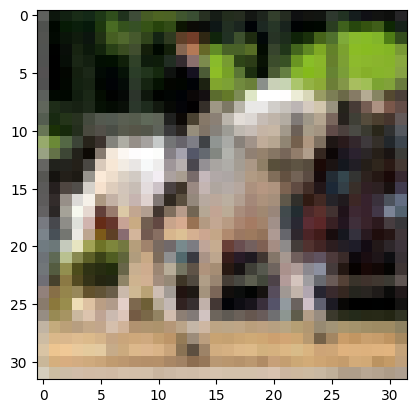

In [68]:
plt.imshow(xtrain_scale[1200])

In [69]:
cnn_model.predict(xtest_scale[2000].reshape((1,)+xtest_scale[2000].shape))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


array([[3.2455413e-05, 9.9471587e-01, 1.1458993e-06, 1.4513540e-06,
        3.3744599e-10, 5.7547334e-07, 7.9211813e-06, 8.6479286e-09,
        3.0087214e-04, 4.9397266e-03]], dtype=float32)

In [70]:
np.argmax(cnn_model.predict(xtest_scale[2000].reshape((1,)+xtest_scale[2000].shape)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


np.int64(1)

In [71]:
images[1]

'Automobile'

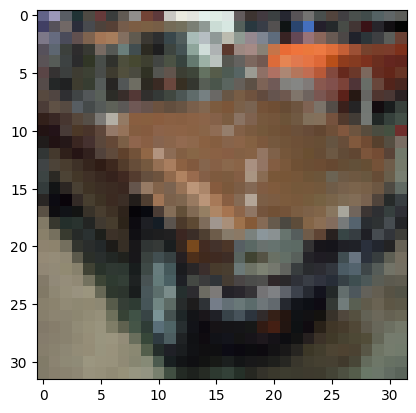

In [72]:
plt.imshow(xtest_scale[2000])

In [73]:
cnn_model.predict(xtrain_scale[60].reshape((1,)+xtrain_scale[60].shape))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


array([[2.2227639e-12, 1.0000000e+00, 3.2943976e-21, 7.5028215e-20,
        3.3671136e-34, 4.2299452e-21, 8.3064185e-20, 5.9362631e-27,
        1.2623315e-10, 6.9250483e-10]], dtype=float32)

In [74]:
np.argmax(cnn_model.predict(xtrain_scale[60].reshape((1,)+xtrain_scale[60].shape)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


np.int64(1)

In [75]:
images[1]

'Automobile'

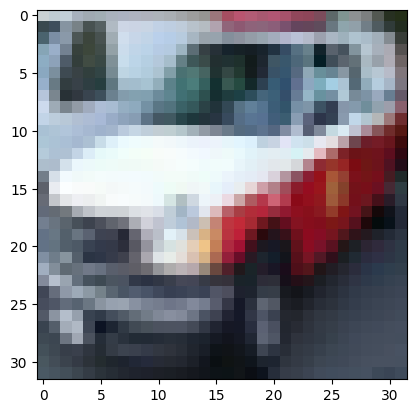

In [76]:
plt.imshow(xtrain_scale[60])

In [77]:
cnn_model.predict(xtrain_scale[3456].reshape((1,)+ xtrain_scale[3456].shape))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


array([[8.5021625e-04, 2.3392624e-05, 1.1682857e-02, 7.5204158e-01,
        3.4951957e-04, 2.2849272e-01, 5.4624756e-03, 9.9942449e-04,
        2.2125820e-05, 7.5710326e-05]], dtype=float32)

In [78]:
np.argmax(cnn_model.predict(xtrain_scale[3456].reshape((1,)+ xtrain_scale[3456].shape)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


np.int64(3)

In [79]:
images[3]

'Cat'

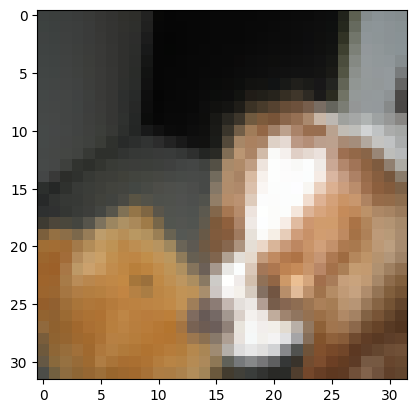

In [80]:
plt.imshow(xtrain_scale[3456])

In [81]:
ytrain[3456]

array([5], dtype=uint8)

In [82]:
from google.colab import files
uploaded = files.upload()

Saving Happy Golden Retriever Puppy.png to Happy Golden Retriever Puppy (1).png


In [83]:
from PIL import Image
import numpy as np

# Load image
img = Image.open(next(iter(uploaded)))

# Make sure it is RGB
img = img.convert("RGB")

# Resize to 32x32
img = img.resize((32, 32))

# Convert to numpy array
img_array = np.array(img)

print("Image shape:", img_array.shape)

Image shape: (32, 32, 3)


In [84]:
img_array = np.expand_dims(img_array, axis=0)

print("Prediction input shape:", img_array.shape)

Prediction input shape: (1, 32, 32, 3)


In [85]:
cnn_model.predict(img_array)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step


array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]], dtype=float32)

In [86]:
np.argmax(cnn_model.predict(img_array))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


np.int64(5)

In [87]:
images[5]

'Dog'